<a href="https://colab.research.google.com/github/Ananyashreee/CE766_project/blob/main/CE766_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Please upload the hirakud_daily_data.csv file here and run the code.


In [16]:
# Setup, Directory Creation and Data Ingestion
import os
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Create output folder for figures and tables
os.makedirs("results", exist_ok=True)

data_paths = ["hirakud_daily_data.csv", "/content/hirakud_daily_data.csv", "data/hirakud_daily_data.csv"]
data_file = next((p for p in data_paths if os.path.exists(p)), None)

if data_file is None:
    raise FileNotFoundError("hirakud_daily_data.csv not found. Please upload it to your workspace.")

df = pd.read_csv(data_file)
df["Date"] = pd.to_datetime(df["Date"])

print(f"Dataset Loaded Successfully: {len(df):,} daily records ({df['Date'].min().date()} to {df['Date'].max().date()}).")
print(f"Historical Inflow Peak: {df['Inflow_cumec'].max():,.1f} m3/s (Record 2003 Monsoon Flood)")
print(f"Mean Annual Inflow   : {(df.groupby('Year')['Inflow_MCM'].sum().mean() / 1000):.2f} BCM/year")
print(f"Mean Annual Demand   : {(df.groupby('Year')['Demand_MCM'].sum().mean() / 1000):.2f} BCM/year")

Dataset Loaded Successfully: 9,004 daily records (2001-01-01 to 2025-10-31).
Historical Inflow Peak: 47,580.5 m3/s (Record 2003 Monsoon Flood)
Mean Annual Inflow   : 28.13 BCM/year
Mean Annual Demand   : 6.79 BCM/year


In [17]:
# Physical Dam Parameters and Bathymetric Rating Curves
FRL_ft       = 630.0            # Full Reservoir Level (ft)
MDDL_ft      = 590.0            # Minimum Drawdown Level (ft)
S_DEAD       = 840.0            # Dead storage volume below MDDL (MCM)
S_GROSS      = 5896.0           # Gross storage capacity at FRL (MCM)
S_LIVE       = S_GROSS - S_DEAD # Active conservation capacity: 5,056 MCM
AREA_FRL     = 743.0            # Water spread area at FRL (sq km)
SAFE_Q_CUMEC = 11326.0          # Safe carrying capacity at Naraj Delta Head (m3/s)
SAFE_Q_MCM   = SAFE_Q_CUMEC * 0.0864 # Equivalent safe discharge in MCM/day (~978.57 MCM/day)

# Official CWC 1988 Guide Curve Rule (Day of Year -> Permissible Elevation in ft)
# Day of Year: Jul 1 (182), Aug 1 (213), Aug 11 (223), Aug 21 (233), Sep 1 (244), Sep 11 (254), Sep 21 (264), Oct 1 (274)
CWC_DAYS = np.array([182, 213, 223, 233, 244, 254, 264, 274])
CWC_ELEVS = np.array([595.0, 606.0, 612.0, 617.0, 621.0, 626.0, 628.5, 630.0])

def storage_to_elevation(s_mcm):
    """Converts storage (MCM) to elevation (ft) using power-law rating."""
    s = np.clip(s_mcm, S_DEAD, S_GROSS)
    return MDDL_ft + (FRL_ft - MDDL_ft) * (((s - S_DEAD) / S_LIVE) ** (1.0 / 1.85))

def elevation_to_storage(elev_ft):
    """Converts elevation (ft) to storage (MCM) using power-law rating."""
    e = np.clip(elev_ft, MDDL_ft, FRL_ft)
    return S_DEAD + S_LIVE * (((e - MDDL_ft) / (FRL_ft - MDDL_ft)) ** 1.85)

def get_target_storage(doy, elevs):
    """Interpolates permissible rule curve storage target (MCM) on calendar day of year."""
    if doy < 182 or doy > 274:
        return S_GROSS # Outside monsoon, maintain maximum conservation storage (FRL)
    target_elev = np.interp(doy, CWC_DAYS, elevs)
    return elevation_to_storage(target_elev)


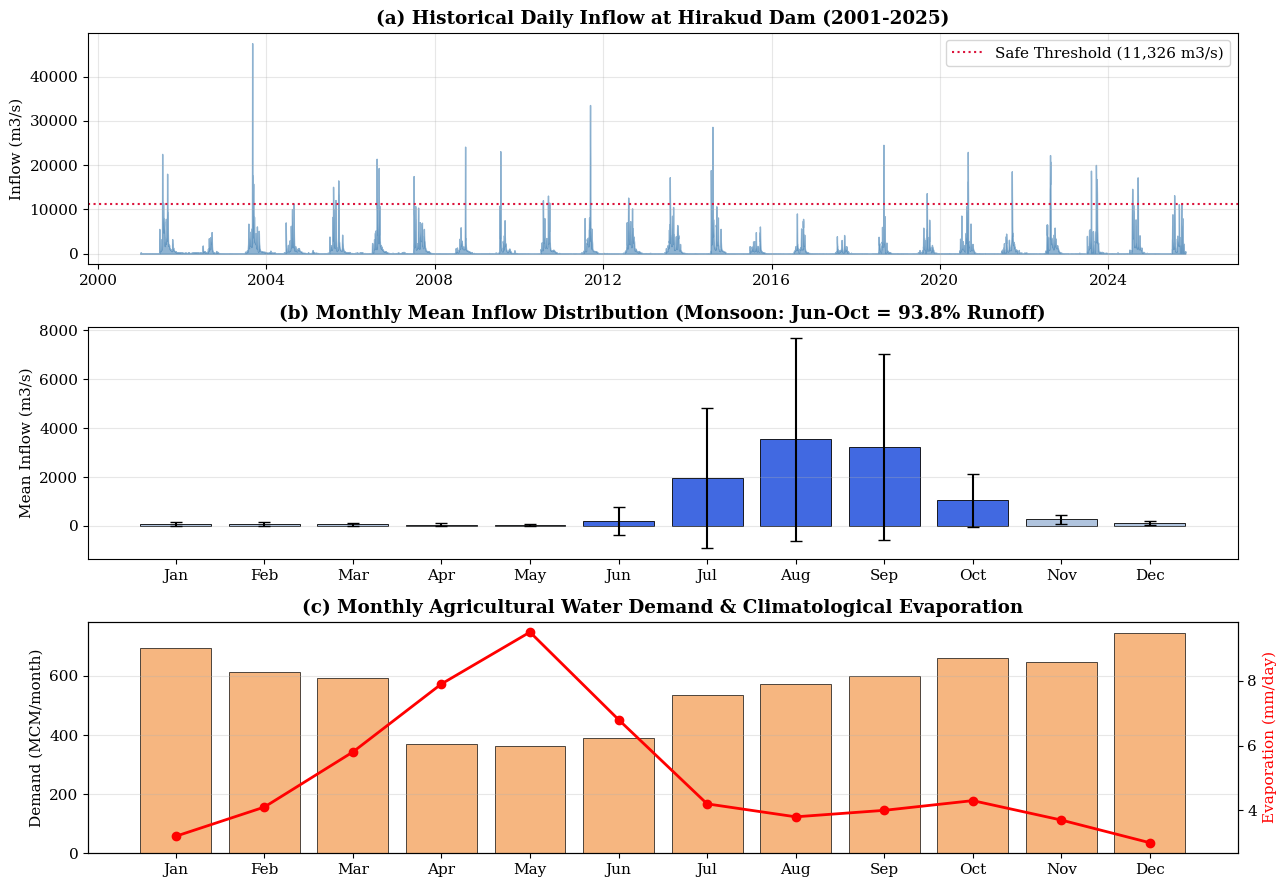

In [18]:
# Exploratory Data Hydrographs and Seasonal Inflow-Demand Climatology
fig, axes = plt.subplots(3, 1, figsize=(13, 9))

# (a) Historical Inflow Hydrograph (2001-2025)
axes[0].fill_between(df["Date"], df["Inflow_cumec"], color="steelblue", alpha=0.6)
axes[0].axhline(SAFE_Q_CUMEC, color="crimson", ls=":", lw=1.5, label=f"Safe Threshold ({SAFE_Q_CUMEC:,.0f} m3/s)")
axes[0].set_ylabel("Inflow (m3/s)")
axes[0].set_title("(a) Historical Daily Inflow at Hirakud Dam (2001-2025)", weight="bold")
axes[0].legend(loc="upper right")
axes[0].grid(True, alpha=0.3)

# (b) Monthly Climatological Inflow Distribution
mon_mean = df.groupby("Month")["Inflow_cumec"].mean()
mon_std  = df.groupby("Month")["Inflow_cumec"].std()
months   = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
bar_colors = ["royalblue" if m in [6,7,8,9,10] else "lightsteelblue" for m in range(1,13)]
axes[1].bar(months, mon_mean, yerr=mon_std, color=bar_colors, capsize=4, edgecolor="black", lw=0.6)
axes[1].set_ylabel("Mean Inflow (m3/s)")
axes[1].set_title("(b) Monthly Mean Inflow Distribution (Monsoon: Jun-Oct = 93.8% Runoff)", weight="bold")
axes[1].grid(True, alpha=0.3, axis="y")

# (c) Monthly Irrigation Demand and Pan Evaporation
mon_dem = df.groupby("Month")["Demand_MCM"].sum() / df["Year"].nunique()
mon_ev  = df.groupby("Month")["Evap_mm"].mean()
ax_tw   = axes[2].twinx()
axes[2].bar(months, mon_dem, color="sandybrown", alpha=0.8, edgecolor="black", lw=0.6, label="Irrigation Demand (MCM/mo)")
ax_tw.plot(months, mon_ev, "r-o", lw=2, label="Pan Evaporation (mm/day)")
axes[2].set_ylabel("Demand (MCM/month)")
ax_tw.set_ylabel("Evaporation (mm/day)", color="red")
axes[2].set_title("(c) Monthly Agricultural Water Demand & Climatological Evaporation", weight="bold")
axes[2].grid(True, alpha=0.3, axis="y")

plt.tight_layout()
plt.savefig("results/fig0_input_data_overview.png", dpi=200)
plt.show()

In [19]:
# Daily Reservoir Mass Balance Continuity Simulation Engine
def simulate_reservoir(df, policy="CWC_RULE", custom_elevs=None, hedge_params=None, demand_mult=1.0, inflow_mult=1.0):
    n = len(df)
    inflows = df["Inflow_MCM"].values.copy()
    demands = df["Demand_MCM"].values.copy() * demand_mult
    evaps   = df["Evap_mm"].values
    doys    = df["DayOfYear"].values
    months  = df["Month"].values

    if inflow_mult != 1.0:
        for i in range(n):
            if months[i] in [6, 7, 8, 9, 10]: # Monsoon scaling
                inflows[i] *= inflow_mult

    storage   = np.zeros(n)
    elevation = np.zeros(n)
    rel_irr   = np.zeros(n)
    rel_flood = np.zeros(n)
    deficit   = np.zeros(n)
    current_s = S_GROSS # Initialize full at FRL

    for t in range(n):
        I_t = inflows[t]
        D_t = demands[t]
        doy = doys[t]

        # Evaporation loss from dynamic surface area
        area = AREA_FRL * ((current_s / S_GROSS) ** 0.68)
        evap_loss = area * evaps[t] * 1e-3
        water_avail = current_s + I_t - evap_loss

        # Drought Hedging Mechanism
        if policy == "OPTIMIZED" and hedge_params is not None:
            h_elev, h_frac = hedge_params
            if current_s < elevation_to_storage(h_elev) and (doy < 182 or doy > 274):
                eff_demand = D_t * h_frac
            else:
                eff_demand = D_t
        else:
            eff_demand = D_t

        # 1. Irrigation release priority (from live storage above MDDL)
        avail_for_irr = max(0.0, water_avail - S_DEAD)
        r_irr = min(avail_for_irr, eff_demand)
        rel_irr[t] = r_irr
        deficit[t] = max(0.0, D_t - r_irr)
        water_left = water_avail - r_irr

        # 2. Rule curve target storage
        if policy == "SOP":
            s_target = S_GROSS
        elif policy == "CWC_RULE":
            s_target = get_target_storage(doy, CWC_ELEVS)
        else: # OPTIMIZED
            s_target = get_target_storage(doy, custom_elevs)

        # 3. Flood evacuation release with hydraulic throttling
        r_flood = 0.0
        if water_left > s_target:
            excess = water_left - s_target
            if policy == "SOP":
                r_flood = excess
                water_left = s_target
            else:
                evac = min(excess, SAFE_Q_MCM)
                if (water_left - evac) > S_GROSS:
                    evac += (water_left - evac - S_GROSS)
                r_flood = evac
                water_left -= r_flood

        rel_flood[t] = r_flood
        current_s = np.clip(water_left, S_DEAD, S_GROSS)
        storage[t] = current_s
        elevation[t] = storage_to_elevation(current_s)

    out = df.copy()
    out["Storage_MCM"] = storage
    out["Elevation_ft"] = elevation
    out["Release_Irr_MCM"] = rel_irr
    out["Release_Flood_MCM"] = rel_flood
    out["Total_Outflow_MCM"] = rel_irr + rel_flood
    out["Total_Outflow_cumec"] = (rel_irr + rel_flood) / 0.0864
    out["Deficit_MCM"] = deficit
    out["Demand_Target_MCM"] = demands
    return out


In [20]:
# Hashimoto (1982) Performance Metrics Computation
def compute_metrics(sim_df):
    tot_dem = sim_df["Demand_Target_MCM"].sum()
    tot_irr = sim_df["Release_Irr_MCM"].sum()
    vol_rel = (tot_irr / tot_dem) * 100.0

    is_fail = sim_df["Deficit_MCM"].values > 1e-3
    time_rel = (1.0 - is_fail.sum() / len(sim_df)) * 100.0

    n_fail = is_fail.sum()
    n_recover = sum(1 for i in range(len(is_fail) - 1) if is_fail[i] and not is_fail[i + 1])
    resilience = (n_recover / n_fail) if n_fail > 0 else 1.0

    monthly_def = sim_df.groupby(["Year", "Month"])["Deficit_MCM"].sum()
    vulnerability = monthly_def.max() if len(monthly_def) > 0 else 0.0

    f1 = np.sum((sim_df["Deficit_MCM"] / sim_df["Demand_Target_MCM"]) ** 2) / len(sim_df)
    f2 = sim_df["Total_Outflow_cumec"].max()
    days_exceed = int((sim_df["Total_Outflow_cumec"] > SAFE_Q_CUMEC).sum())

    return {
        "F1_Deficit_Index": f1,
        "F2_Peak_Q_cumec": f2,
        "Vol_Reliability_pct": round(vol_rel, 2),
        "Time_Reliability_pct": round(time_rel, 2),
        "Resilience": round(resilience, 4),
        "Vulnerability_Max_Month_MCM": round(vulnerability, 2),
        "Days_Exceeding_Safe_Q": days_exceed
    }


In [21]:
# Fast Vectorized NSGA-II Multi-Objective Optimization Engine and Non-dominated Pareto Solutions
def fast_eval(elevs, h_elev, h_frac, inflows, demands, evaps, doys, n):
    t_elevs = np.interp(np.arange(1, 367), CWC_DAYS, elevs)
    t_elevs[:181] = 630.0
    t_elevs[274:] = 630.0
    t_s = S_DEAD + S_LIVE * (((t_elevs - MDDL_ft) / (FRL_ft - MDDL_ft)) ** 1.85)
    h_s = S_DEAD + S_LIVE * (((h_elev - MDDL_ft) / (FRL_ft - MDDL_ft)) ** 1.85)

    cur_s = S_GROSS
    dsq = 0.0
    max_q = 0.0

    for t in range(n):
        doy = doys[t]
        d_t = demands[t]
        area = AREA_FRL * ((cur_s / S_GROSS) ** 0.68)
        w = cur_s + inflows[t] - area * evaps[t] * 1e-3

        eff_d = d_t * h_frac if (cur_s < h_s and (doy < 182 or doy > 274)) else d_t
        r_irr = min(max(0.0, w - S_DEAD), eff_d)
        dsq += ((d_t - r_irr) / d_t) ** 2
        w -= r_irr

        r_flood = 0.0
        if w > t_s[doy - 1]:
            evac = min(w - t_s[doy - 1], SAFE_Q_MCM)
            if w - evac > S_GROSS:
                evac += (w - evac - S_GROSS)
            r_flood = evac
            w -= evac

        q = (r_irr + r_flood) / 0.0864
        if q > max_q:
            max_q = q
        cur_s = min(max(w, S_DEAD), S_GROSS)

    return dsq / n, max_q

def sample_chromosome(flavor="random"):
    ranges = {
        "flood":        [(590,594),(596,602),(602,608),(607,613),(612,618),(617,623),(622,627),(627,629.5)],
        "conservation": [(596,604),(606,614),(612,618),(616,622),(620,626),(624,628.5),(628,629.8),(630,630)],
        "random":       [(591,598),(598,608),(605,614),(610,619),(616,624),(621,627.5),(625,629.5),(630,630)],
    }
    hedges = {
        "flood":        ((596,608),(0.75,0.90)),
        "conservation": ((592,598),(0.85,0.98)),
        "random":       ((594,605),(0.78,0.95))
    }
    elevs = sorted([np.random.uniform(*r) for r in ranges[flavor]])
    elevs[-1] = 630.0
    h_lo, h_hi = hedges[flavor]
    return {"elevs": elevs, "hedging": (np.random.uniform(*h_lo), np.random.uniform(*h_hi))}

def dominates(a, b):
    return (a["f1"] <= b["f1"] and a["f2"] <= b["f2"]) and (a["f1"] < b["f1"] or a["f2"] < b["f2"])

def run_nsga2(df, pop_size=36, generations=14, seed=42):
    np.random.seed(seed)
    inflows = df["Inflow_MCM"].values
    demands = df["Demand_MCM"].values
    evaps   = df["Evap_mm"].values
    doys    = df["DayOfYear"].values
    n       = len(df)

    pop = []
    flavors = ["flood"] * (pop_size // 3) + ["conservation"] * (pop_size // 3) + ["random"] * (pop_size // 3)
    for fl in flavors:
        ind = sample_chromosome(fl)
        ind["f1"], ind["f2"] = fast_eval(ind["elevs"], ind["hedging"][0], ind["hedging"][1], inflows, demands, evaps, doys, n)
        pop.append(ind)

    for _ in range(generations):
        kids = []
        for __ in range(pop_size):
            p1 = pop[np.random.randint(0, pop_size)]
            p2 = pop[np.random.randint(0, pop_size)]
            alpha = np.random.rand()
            c_elevs = sorted([alpha * a + (1 - alpha) * b for a, b in zip(p1["elevs"], p2["elevs"])])
            if np.random.rand() < 0.35:
                idx = np.random.randint(0, 7)
                c_elevs[idx] += np.random.normal(0, 0.5)
                c_elevs = sorted(np.clip(c_elevs, 590.0, 630.0))
            c_elevs[-1] = 630.0

            c_hedge = (
                float(np.clip(alpha * p1["hedging"][0] + (1 - alpha) * p2["hedging"][0] + np.random.normal(0, 0.4), 591, 610)),
                float(np.clip(alpha * p1["hedging"][1] + (1 - alpha) * p2["hedging"][1] + np.random.normal(0, 0.02), 0.70, 0.98))
            )
            kid = {"elevs": c_elevs, "hedging": c_hedge}
            kid["f1"], kid["f2"] = fast_eval(c_elevs, c_hedge[0], c_hedge[1], inflows, demands, evaps, doys, n)
            kids.append(kid)

        combined = pop + kids
        survivors = []
        pool = combined[:]
        while pool and len(survivors) < pop_size:
            front = [ind for i, ind in enumerate(pool) if not any(dominates(other, ind) for j, other in enumerate(pool) if i != j)]
            for ind in front:
                pool.remove(ind)
            survivors.extend(front)
        pop = survivors[:pop_size]

    pareto = [ind for i, ind in enumerate(pop) if not any(dominates(other, ind) for j, other in enumerate(pool) if i != j)]
    return sorted(pareto, key=lambda x: x["f1"])

print("NSGA-II multi-objective engine configured.")
print("Executing NSGA-II Multi-Objective Optimization...")
t0 = time.time()
pareto_solutions = run_nsga2(df, pop_size=36, generations=14, seed=42)
print(f"Optimization completed in {time.time() - t0:.2f} s. Discovered {len(pareto_solutions)} non-dominated Pareto solutions.")

pareto_df = pd.DataFrame([{
    "Solution": f"P{i+1}",
    "f1_Deficit_Index": round(p["f1"], 6),
    "f2_Peak_Q_cumec": round(p["f2"], 1),
    "Hedge_Elev_ft": round(p["hedging"][0], 1),
    "Hedge_Ratio": round(p["hedging"][1], 2),
    "Elevations_ft": str([round(float(x), 1) for x in p["elevs"]])
} for i, p in enumerate(pareto_solutions)])

pareto_df.to_csv("results/pareto_front_solutions.csv", index=False)
print("Saved: results/pareto_front_solutions.csv")
print(pareto_df[["Solution", "f1_Deficit_Index", "f2_Peak_Q_cumec", "Hedge_Elev_ft", "Hedge_Ratio"]].to_string(index=False))

NSGA-II multi-objective engine configured.
Executing NSGA-II Multi-Objective Optimization...
Optimization completed in 13.01 s. Discovered 36 non-dominated Pareto solutions.
Saved: results/pareto_front_solutions.csv
Solution  f1_Deficit_Index  f2_Peak_Q_cumec  Hedge_Elev_ft  Hedge_Ratio
      P1          0.000000          27598.6          600.8         0.90
      P2          0.000000          27619.0          601.1         0.88
      P3          0.000008          26793.4          601.3         0.94
      P4          0.000010          27590.7          601.4         0.88
      P5          0.000011          25760.4          601.5         0.94
      P6          0.000012          25659.6          600.8         0.94
      P7          0.000013          26595.1          600.7         0.92
      P8          0.000015          25362.5          600.6         0.92
      P9          0.000015          26314.9          601.4         0.91
     P10          0.000017          26232.3          600.7      

In [22]:
# Long-Term Policy Simulations
# Balanced Compromise Policy (Knee Point on the Pareto frontier)
OPT_ELEVS = [595.3, 602.9, 607.1, 610.0, 615.7, 621.0, 626.7, 630.0]
OPT_HEDGE = (598.0, 0.85)

print("Simulating operational policies across 2001-2025...")
sim_sop = simulate_reservoir(df, policy="SOP")
sim_cwc = simulate_reservoir(df, policy="CWC_RULE")
sim_opt = simulate_reservoir(df, policy="OPTIMIZED", custom_elevs=OPT_ELEVS, hedge_params=OPT_HEDGE)

m_sop = compute_metrics(sim_sop)
m_cwc = compute_metrics(sim_cwc)
m_opt = compute_metrics(sim_opt)
print("All 3 policy simulations completed.")


Simulating operational policies across 2001-2025...
All 3 policy simulations completed.


In [23]:
# Table 1 - Long-Term Policy Performance Comparison
inflow_max = df["Inflow_cumec"].max()

table1 = pd.DataFrame([
    {
        "Operational Policy": "Standard Operating Policy (SOP)",
        "Peak Outflow (m3/s)": round(m_sop["F2_Peak_Q_cumec"], 1),
        "Flood Attenuation (%)": round((1.0 - m_sop["F2_Peak_Q_cumec"] / inflow_max) * 100.0, 1),
        "Days Exceeding Safe Q": m_sop["Days_Exceeding_Safe_Q"],
        "Volumetric Reliability (%)": round(m_sop["Vol_Reliability_pct"], 1),
        "Time Reliability (%)": round(m_sop["Time_Reliability_pct"], 1),
        "Deficit Index (F1)": f"{m_sop['F1_Deficit_Index']:.6f}"
    },
    {
        "Operational Policy": "Official CWC 1988 Rule Curve",
        "Peak Outflow (m3/s)": round(m_cwc["F2_Peak_Q_cumec"], 1),
        "Flood Attenuation (%)": round((1.0 - m_cwc["F2_Peak_Q_cumec"] / inflow_max) * 100.0, 1),
        "Days Exceeding Safe Q": m_cwc["Days_Exceeding_Safe_Q"],
        "Volumetric Reliability (%)": round(m_cwc["Vol_Reliability_pct"], 1),
        "Time Reliability (%)": round(m_cwc["Time_Reliability_pct"], 1),
        "Deficit Index (F1)": f"{m_cwc['F1_Deficit_Index']:.6f}"
    },
    {
        "Operational Policy": "Optimized Policy (NSGA-II Knee Point)",
        "Peak Outflow (m3/s)": round(m_opt["F2_Peak_Q_cumec"], 1),
        "Flood Attenuation (%)": round((1.0 - m_opt["F2_Peak_Q_cumec"] / inflow_max) * 100.0, 1),
        "Days Exceeding Safe Q": m_opt["Days_Exceeding_Safe_Q"],
        "Volumetric Reliability (%)": round(m_opt["Vol_Reliability_pct"], 1),
        "Time Reliability (%)": round(m_opt["Time_Reliability_pct"], 1),
        "Deficit Index (F1)": f"{m_opt['F1_Deficit_Index']:.6f}"
    }
])

table1.to_csv("results/table1_policy_comparison.csv", index=False)
print("TABLE 1: LONG-TERM POLICY PERFORMANCE COMPARISON (2001-2025):")
print(table1.to_string(index=False))

TABLE 1: LONG-TERM POLICY PERFORMANCE COMPARISON (2001-2025):
                   Operational Policy  Peak Outflow (m3/s)  Flood Attenuation (%)  Days Exceeding Safe Q  Volumetric Reliability (%)  Time Reliability (%) Deficit Index (F1)
      Standard Operating Policy (SOP)              47547.9                    0.1                     77                       100.0                 100.0           0.000000
         Official CWC 1988 Rule Curve              36471.7                   23.3                    159                       100.0                  99.9           0.000140
Optimized Policy (NSGA-II Knee Point)              25164.3                   47.1                    168                       100.0                  99.7           0.000134


In [24]:
# Table 2 - Hashimoto RRV Metrics across Hydrological Regimes
regimes = [
    ("Extreme Flood (2003)", df["Year"] == 2003),
    ("Normal Inflow (2010)", df["Year"] == 2010),
    ("Severe Drought (2002)", df["Year"] == 2002),
    ("Severe Drought (2017)", df["Year"] == 2017),
    ("Full Record (2001-2025)", pd.Series(True, index=df.index))
]
rrv_rows = []
for r_name, r_mask in regimes:
    for p_name, s_df in [("SOP", sim_sop[r_mask]),
                         ("CWC 1988", sim_cwc[r_mask]),
                         ("Optimized", sim_opt[r_mask])]:
        m = compute_metrics(s_df)
        rrv_rows.append({
            "Hydrological Regime": r_name,
            "Policy": p_name,
            "Time Reliability (Rt %)": round(m["Time_Reliability_pct"], 1),
            "Volumetric Reliability (Rv %)": round(m["Vol_Reliability_pct"], 1),
            "Resilience (gamma)": round(m["Resilience"], 3),
            "Vulnerability (Max Month MCM)": round(m["Vulnerability_Max_Month_MCM"], 1),
            "Peak Outflow (m3/s)": round(m["F2_Peak_Q_cumec"], 1)
        })

table2 = pd.DataFrame(rrv_rows)
table2.to_csv("results/table2_hashimoto_rrv.csv", index=False)
print("TABLE 2: HASHIMOTO RRV METRICS ACROSS HYDROLOGICAL REGIMES:")
print(table2.to_string(index=False))

TABLE 2: HASHIMOTO RRV METRICS ACROSS HYDROLOGICAL REGIMES:
    Hydrological Regime    Policy  Time Reliability (Rt %)  Volumetric Reliability (Rv %)  Resilience (gamma)  Vulnerability (Max Month MCM)  Peak Outflow (m3/s)
   Extreme Flood (2003)       SOP                    100.0                          100.0               1.000                            0.0              47547.9
   Extreme Flood (2003)  CWC 1988                    100.0                          100.0               1.000                            0.0              36471.7
   Extreme Flood (2003) Optimized                     96.2                           99.6               0.071                           27.3              25164.3
   Normal Inflow (2010)       SOP                    100.0                          100.0               1.000                            0.0              13106.8
   Normal Inflow (2010)  CWC 1988                    100.0                          100.0               1.000                     

In [25]:
# Table 3 - Climate and Demand Sensitivity Stress-Testing
scenarios = [
    ("Baseline Conditions", 1.0, 1.0),
    ("Scenario A: Demand Growth (+15%)", 1.15, 1.0),
    ("Scenario B: Drier Monsoon (-10% Inflow)", 1.0, 0.90),
    ("Scenario C: Combined Stress (+15% Demand, -10% Inflow)", 1.15, 0.90)
]
stress_rows = []
for s_name, d_mult, inf_mult in scenarios:
    for p_name, p_code, c_el, h_p in [
        ("CWC 1988", "CWC_RULE", None, None),
        ("Optimized", "OPTIMIZED", OPT_ELEVS, OPT_HEDGE)
    ]:
        sim_s = simulate_reservoir(df, policy=p_code, custom_elevs=c_el, hedge_params=h_p,
                                   demand_mult=d_mult, inflow_mult=inf_mult)
        oct1_mask = (sim_s["Month"] == 10) & (sim_s["Day"] == 1)
        mean_oct1 = sim_s.loc[oct1_mask, "Elevation_ft"].mean()
        min_oct1 = sim_s.loc[oct1_mask, "Elevation_ft"].min()
        pct_frl = (sim_s.loc[oct1_mask, "Elevation_ft"] >= 629.5).mean() * 100.0
        m_s = compute_metrics(sim_s)

        stress_rows.append({
            "Stress Scenario": s_name,
            "Policy": p_name,
            "Volumetric Reliability (%)": round(m_s["Vol_Reliability_pct"], 1),
            "Time Reliability (%)": round(m_s["Time_Reliability_pct"], 1),
            "Mean Oct 1 Elevation (ft)": round(mean_oct1, 1),
            "Min Oct 1 Elevation (ft)": round(min_oct1, 1),
            "Years Attaining FRL (%)": round(pct_frl, 1),
            "Max Monthly Deficit (MCM)": round(m_s["Vulnerability_Max_Month_MCM"], 1),
            "Peak Outflow (m3/s)": round(m_s["F2_Peak_Q_cumec"], 1)
        })

table3 = pd.DataFrame(stress_rows)
table3.to_csv("results/table3_sensitivity.csv", index=False)
print("TABLE 3: SENSITIVITY STRESS-TESTING (CLIMATE & DEMAND):")
print(table3.to_string(index=False))

TABLE 3: SENSITIVITY STRESS-TESTING (CLIMATE & DEMAND):
                                       Stress Scenario    Policy  Volumetric Reliability (%)  Time Reliability (%)  Mean Oct 1 Elevation (ft)  Min Oct 1 Elevation (ft)  Years Attaining FRL (%)  Max Monthly Deficit (MCM)  Peak Outflow (m3/s)
                                   Baseline Conditions  CWC 1988                       100.0                  99.9                      629.7                     627.8                     84.0                       27.7              36471.7
                                   Baseline Conditions Optimized                       100.0                  99.7                      628.8                     623.2                     76.0                       27.3              25164.3
                      Scenario A: Demand Growth (+15%)  CWC 1988                        99.8                  99.7                      629.6                     627.2                     84.0                      105.2  

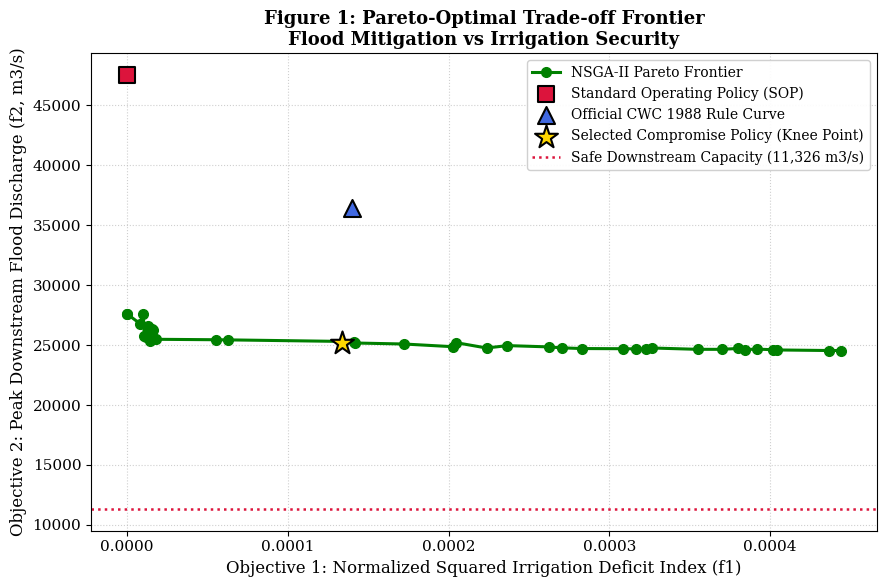

Saved: results/fig1_pareto_front_tradeoff.png


In [26]:
# Visual 1 (Figure 1) - Pareto-Optimal Trade-off Frontier
fig1, ax1 = plt.subplots(figsize=(9, 6))
plt.rcParams.update({"font.family": "serif", "font.size": 11})

f1_front = [sol["f1"] for sol in pareto_solutions]
f2_front = [sol["f2"] for sol in pareto_solutions]

# Live Pareto frontier curve
ax1.plot(f1_front, f2_front, "g-o", linewidth=2.2, markersize=7, label="NSGA-II Pareto Frontier", zorder=3)

# Benchmark policies
ax1.scatter([m_sop["F1_Deficit_Index"]], [m_sop["F2_Peak_Q_cumec"]], color="crimson", marker="s", s=140, edgecolors="black", linewidths=1.5, label="Standard Operating Policy (SOP)", zorder=4)
ax1.scatter([m_cwc["F1_Deficit_Index"]], [m_cwc["F2_Peak_Q_cumec"]], color="royalblue", marker="^", s=150, edgecolors="black", linewidths=1.5, label="Official CWC 1988 Rule Curve", zorder=4)
ax1.scatter([m_opt["F1_Deficit_Index"]], [m_opt["F2_Peak_Q_cumec"]], color="gold", marker="*", s=300, edgecolors="black", linewidths=1.5, label="Selected Compromise Policy (Knee Point)", zorder=5)

ax1.axhline(SAFE_Q_CUMEC, color="crimson", linestyle=":", linewidth=1.8, label=f"Safe Downstream Capacity ({SAFE_Q_CUMEC:,.0f} m3/s)")
ax1.set_xlabel("Objective 1: Normalized Squared Irrigation Deficit Index (f1)", fontsize=12)
ax1.set_ylabel("Objective 2: Peak Downstream Flood Discharge (f2, m3/s)", fontsize=12)
ax1.set_title("Figure 1: Pareto-Optimal Trade-off Frontier\nFlood Mitigation vs Irrigation Security", fontsize=13, weight="bold")
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend(loc="upper right", framealpha=0.92, fontsize=10)
plt.tight_layout()

fig1_path = "results/fig1_pareto_front_tradeoff.png"
fig1.savefig(fig1_path, dpi=300)
plt.show()
print(f"Saved: {fig1_path}")

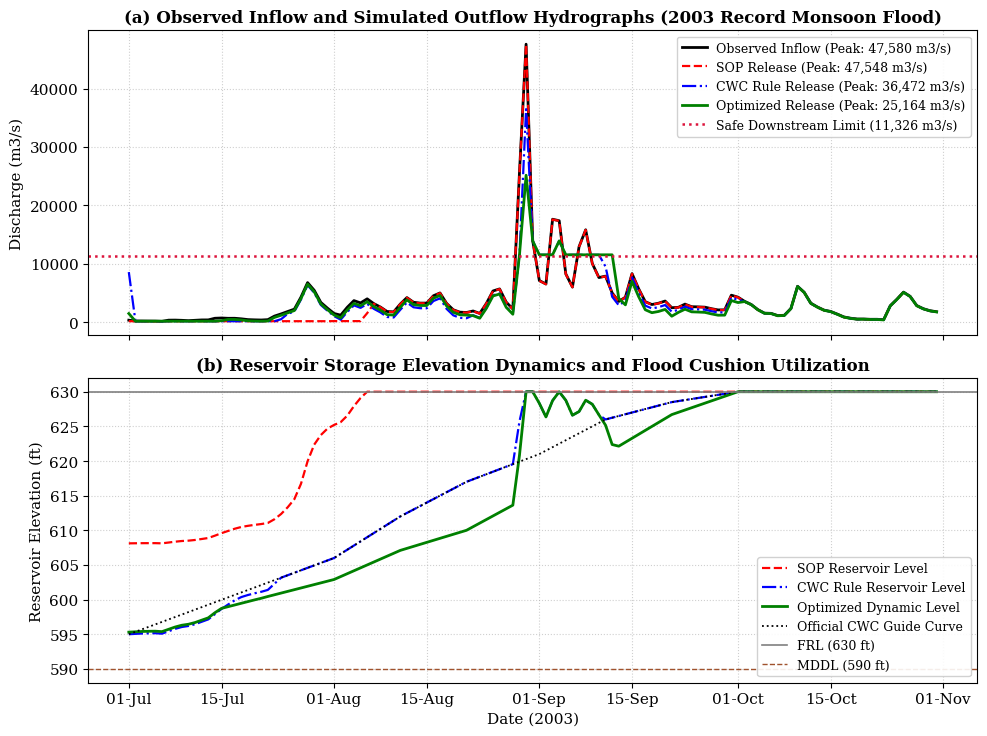

Saved: results/fig2_extreme_flood_routing_2003.png


In [27]:
# Visual 2 (Figure 2) - 2003 Extreme Flood Routing & Elevation Dynamics
mask_2003 = (df["Date"] >= "2003-07-01") & (df["Date"] <= "2003-10-31")
d_sub = df.loc[mask_2003, "Date"]
q_in  = df.loc[mask_2003, "Inflow_cumec"]
q_sop = sim_sop.loc[mask_2003, "Total_Outflow_cumec"]
q_cwc = sim_cwc.loc[mask_2003, "Total_Outflow_cumec"]
q_opt = sim_opt.loc[mask_2003, "Total_Outflow_cumec"]

el_sop = sim_sop.loc[mask_2003, "Elevation_ft"]
el_cwc = sim_cwc.loc[mask_2003, "Elevation_ft"]
el_opt = sim_opt.loc[mask_2003, "Elevation_ft"]
cwc_guide_sub = [np.interp(doy, CWC_DAYS, CWC_ELEVS) for doy in df.loc[mask_2003, "DayOfYear"]]

fig2, (p1, p2) = plt.subplots(2, 1, figsize=(10, 7.5), sharex=True)

# (a) Outflow Hydrographs
p1.plot(d_sub, q_in, "k-", linewidth=2.0, label=f"Observed Inflow (Peak: {q_in.max():,.0f} m3/s)")
p1.plot(d_sub, q_sop, "r--", linewidth=1.6, label=f"SOP Release (Peak: {q_sop.max():,.0f} m3/s)")
p1.plot(d_sub, q_cwc, "b-.", linewidth=1.6, label=f"CWC Rule Release (Peak: {q_cwc.max():,.0f} m3/s)")
p1.plot(d_sub, q_opt, "g-", linewidth=2.0, label=f"Optimized Release (Peak: {q_opt.max():,.0f} m3/s)")
p1.axhline(SAFE_Q_CUMEC, color="crimson", linestyle=":", linewidth=1.8, label=f"Safe Downstream Limit ({SAFE_Q_CUMEC:,.0f} m3/s)")
p1.set_ylabel("Discharge (m3/s)", fontsize=11)
p1.set_title("(a) Observed Inflow and Simulated Outflow Hydrographs (2003 Record Monsoon Flood)", fontsize=12, weight="bold")
p1.grid(True, linestyle=":", alpha=0.6)
p1.legend(loc="upper right", framealpha=0.9, fontsize=9)

# (b) Storage Elevation Dynamics
p2.plot(d_sub, el_sop, "r--", linewidth=1.6, label="SOP Reservoir Level")
p2.plot(d_sub, el_cwc, "b-.", linewidth=1.6, label="CWC Rule Reservoir Level")
p2.plot(d_sub, el_opt, "g-", linewidth=2.0, label="Optimized Dynamic Level")
p2.plot(d_sub, cwc_guide_sub, "k:", linewidth=1.3, label="Official CWC Guide Curve")
p2.axhline(630.0, color="gray", linewidth=1.2, linestyle="-", label="FRL (630 ft)")
p2.axhline(590.0, color="sienna", linewidth=1.0, linestyle="--", label="MDDL (590 ft)")
p2.set_ylabel("Reservoir Elevation (ft)", fontsize=11)
p2.set_xlabel("Date (2003)", fontsize=11)
p2.set_title("(b) Reservoir Storage Elevation Dynamics and Flood Cushion Utilization", fontsize=12, weight="bold")
p2.grid(True, linestyle=":", alpha=0.6)
p2.xaxis.set_major_formatter(mdates.DateFormatter("%d-%b"))
p2.legend(loc="lower right", framealpha=0.9, fontsize=9)

plt.tight_layout()
fig2_path = "results/fig2_extreme_flood_routing_2003.png"
fig2.savefig(fig2_path, dpi=300)
plt.show()
print(f"Saved: {fig2_path}")